# DSCI 552 - Homework 6

Name: Gao Wang  
GitHub Username: Gavinfornever  
USC ID: 8103152166

Run all cells from the repository root. The original APS data remain in `data/`; reusable functions are in `hw6_analysis.py`. Fixed random seed: 552. Figures and outputs are kept compact for the 20-page submission limit.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from hw6_analysis import (
    SEED, load_aps, impute_once, coefficient_of_variation, compact_cv_table,
    plot_correlation, plot_top_features, forest_pipeline, xgb_pipeline,
    cv_xgb_alpha, plot_diagnostics, plot_svm_exercise,
)

plt.rcParams.update({"figure.dpi": 95, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.22})


## 1. Tree-Based Methods

### (a)-(b) APS data and missing-value preparation

The file's first 20 lines are a preamble. `na` indicates missing values. Common approaches include complete-case deletion, median/mode or KNN imputation, iterative imputation, and models that handle missingness directly. Because deleting incomplete rows would discard many observations, this notebook uses feature-wise median imputation. Medians come from training data only; in cross-validation the imputer is refitted on each training fold. All 170 predictors remain available for modeling.

In [2]:
# AI prompt (scope: APS preprocessing): "Read the supplied APS train/test CSVs after their 20-line preambles, map pos/neg labels, fit median imputation only on training rows, and preserve all 170 numeric predictors."
X_train, X_test, y_train, y_test = load_aps()
feature_names = X_train.columns.tolist()
train_values, test_values, imputer = impute_once(X_train, X_test)
assert train_values.shape == (60000, 170) and test_values.shape == (16000, 170)
print(f"Train/test shapes: {X_train.shape} / {X_test.shape}; "
      f"missing cells: {X_train.isna().sum().sum():,} / {X_test.isna().sum().sum():,}.")
display(pd.DataFrame({"train": np.bincount(y_train, minlength=2),
                      "test": np.bincount(y_test, minlength=2)},
                     index=["negative", "positive"]))


Train/test shapes: (60000, 170) / (16000, 170); missing cells: 850,015 / 228,680.


,train,test
negative,59000,15625
positive,1000,375


### (b)ii-v. Coefficients of variation, correlations, feature plots, and imbalance

CV is sample SD divided by mean, calculated after training-only imputation. A zero mean makes CV undefined. The requested floor of square root of 170 is 13. Plots use a log transform for readability and sample 1,500 negative observations only in the scatter plots; box plots use all training rows. A visual association alone cannot establish statistical significance because of noise, correlated features, and multiple comparisons. The 59:1 training ratio is severely imbalanced.

Top 13 of 170 features by training CV:


,mean,sample_sd,CV
cf_000,143107.531250,3.504525e+07,244.888000
co_000,143330.015625,3.504525e+07,244.507004
ad_000,143438.281250,3.504525e+07,244.322998
cs_009,770.510010,1.833278e+05,237.929993
dh_000,4392.640137,5.412441e+05,123.216003
dj_000,37.271000,4.379167e+03,117.494003
ag_000,219.158005,2.036364e+04,92.917999
as_000,125.407997,1.095219e+04,87.333000
ay_009,1149.619995,9.741156e+04,84.734001
ak_000,907.661011,7.299858e+04,80.425003


All 170 CV values (compact table):


,feature 1,CV 1,feature 2,CV 2,feature 3,CV 3,feature 4,CV 4,feature 5,CV 5
0,aa_000,2.451,ab_000,10.383,ac_000,2.310,ad_000,244.323,ae_000,24.200
1,af_000,19.471,ag_000,92.918,ag_001,35.249,ag_002,17.566,ag_003,8.647
2,ag_004,5.463,ag_005,2.956,ag_006,2.357,ag_007,2.859,ag_008,6.221
3,ag_009,33.358,ah_000,2.312,ai_000,18.204,aj_000,44.266,ak_000,80.425
4,al_000,9.173,am_0,9.155,an_000,2.250,ao_000,2.271,ap_000,3.081
5,aq_000,2.857,ar_000,11.354,as_000,87.333,at_000,23.708,au_000,68.883
6,av_000,6.006,ax_000,4.019,ay_000,37.428,ay_001,52.825,ay_002,39.249
7,ay_003,28.735,ay_004,33.752,ay_005,12.525,ay_006,3.053,ay_007,3.314
8,ay_008,3.816,ay_009,84.734,az_000,9.406,az_001,7.721,az_002,13.272
9,az_003,7.527,az_004,2.849,az_005,3.035,az_006,8.881,az_007,16.229


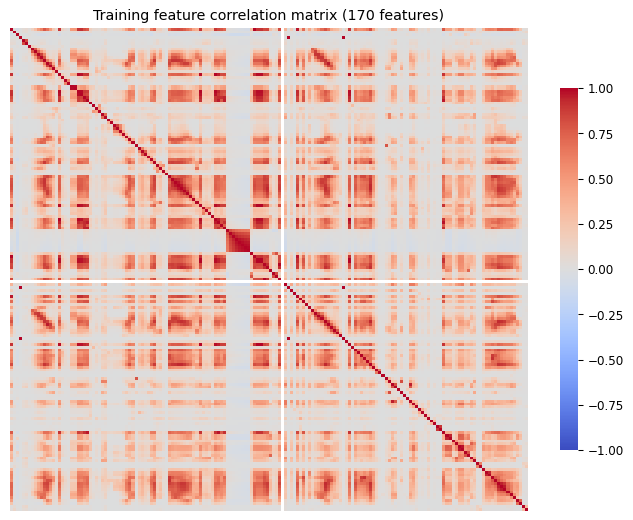

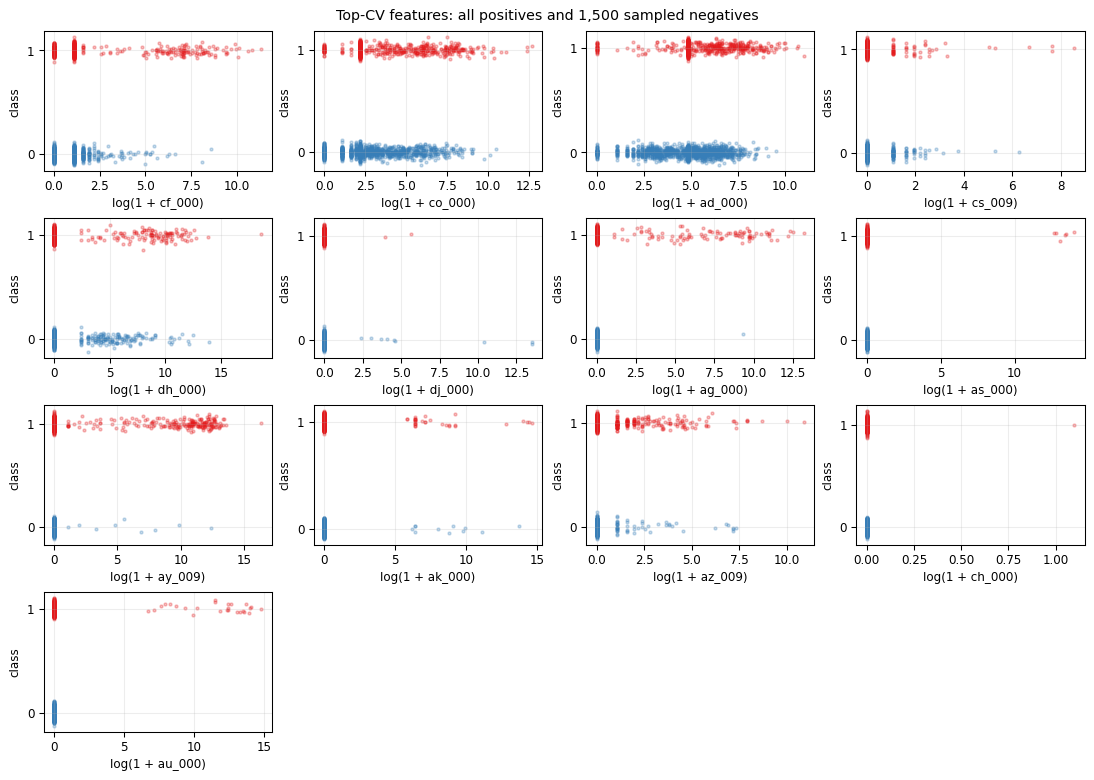

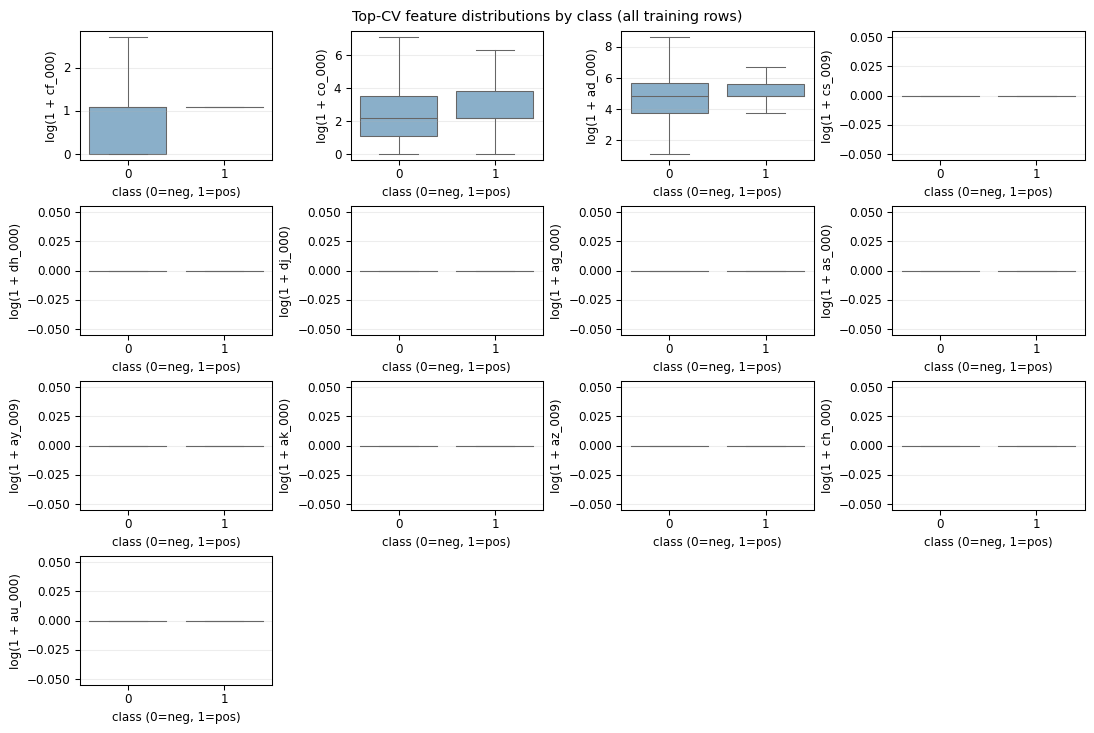

In [3]:
cv_table = coefficient_of_variation(train_values, feature_names)
top_features = cv_table["CV"].replace([np.inf, -np.inf], np.nan).nlargest(13).index.tolist()
print("Top 13 of 170 features by training CV:")
display(cv_table.loc[top_features].round(3))
print("All 170 CV values (compact table):")
display(compact_cv_table(cv_table["CV"]))
plot_correlation(train_values, feature_names)
plot_top_features(train_values, y_train, feature_names, top_features)


### (c)-(d) Ordinary versus class-weighted random forest

The first forest uses no imbalance compensation. The second uses `balanced_subsample`, which weights each class inversely to its frequency within each bootstrap sample. Both have identical tree settings, so only class weighting changes. OOB error is `1 - oob_score_`, measured on bootstrap-excluded training observations; compare it with the untouched test error. Confusion matrices are ordered negative, positive, so false negatives are easy to see.

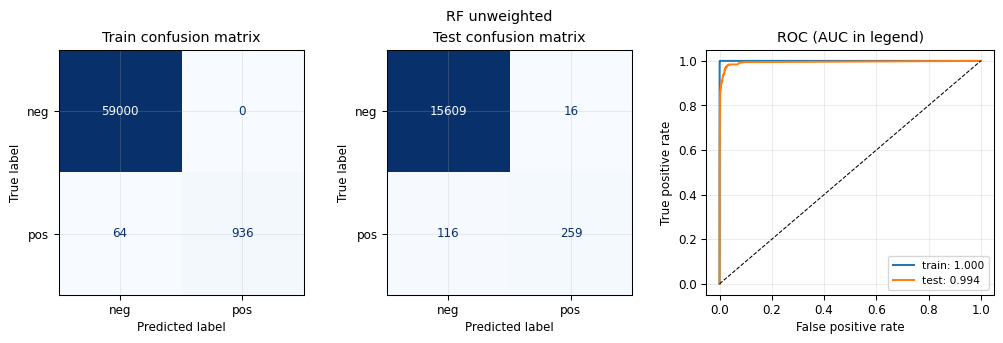

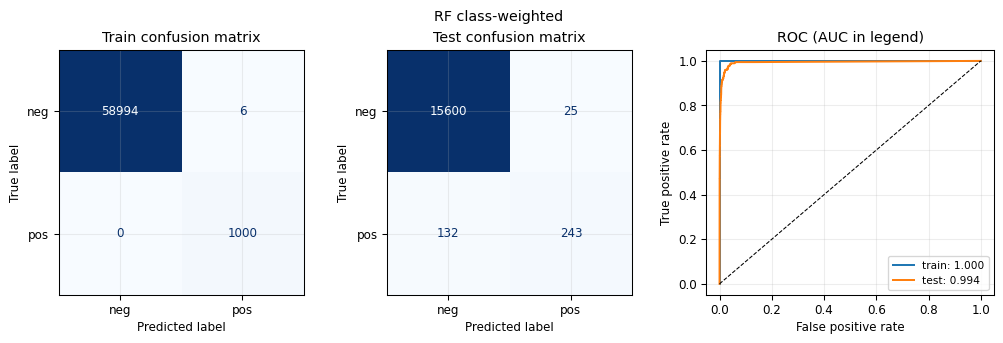

,model,split,TN,FP,FN,TP,error,balanced_accuracy,AUC,OOB_error
0,RF unweighted,train,59000,0,64,936,0.0011,0.9680,1.0000,0.0064
1,RF unweighted,test,15609,16,116,259,0.0082,0.8448,0.9941,0.0064
2,RF class-weighted,train,58994,6,0,1000,0.0001,0.9999,1.0000,0.0070
3,RF class-weighted,test,15600,25,132,243,0.0098,0.8232,0.9935,0.0070


In [4]:
rf_rows = []
for name, balanced in [("RF unweighted", False), ("RF class-weighted", True)]:
    model = forest_pipeline(balanced=balanced).fit(X_train, y_train)
    rows = plot_diagnostics(name, y_train, y_test, model, X_train, X_test)
    oob_error = 1 - model.named_steps["model"].oob_score_
    for row in rows:
        row["OOB_error"] = oob_error
    rf_rows.extend(rows)
display(pd.DataFrame(rf_rows).round(4))


### (e) XGBoost without imbalance compensation

XGBoost's tree booster uses ordinary single-feature splits; `reg_alpha` supplies L1 regularization of leaf weights. It does not literally fit an L1 logistic regression at each internal node, so this is the standard XGBoost approximation suggested by the assignment. Five-fold stratified CV on training data selects `reg_alpha` by balanced accuracy; CV error is also reported as one minus ordinary accuracy. The test set is untouched until final evaluation.

,reg_alpha,CV_error,CV_balanced_accuracy,CV_AUC
0,0.0,0.0072,0.8400,0.9890
1,1.0,0.0072,0.8410,0.9889
2,10.0,0.0080,0.8244,0.9888


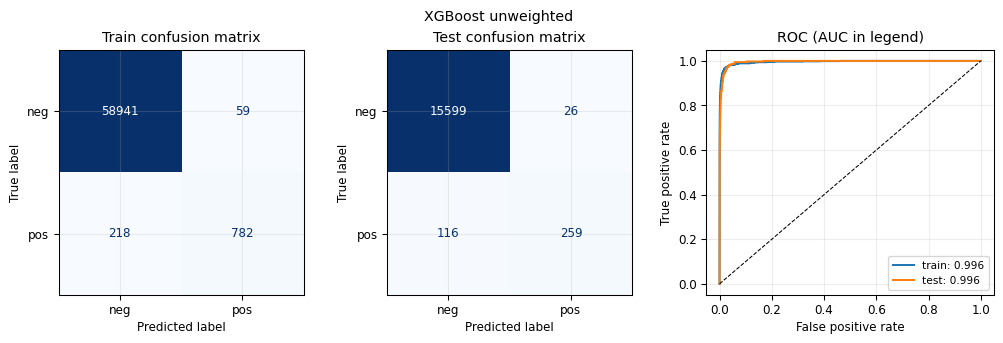

Selected reg_alpha=1; CV error=0.0072; test error=0.0089.


,model,split,TN,FP,FN,TP,error,balanced_accuracy,AUC
0,XGBoost unweighted,train,58941,59,218,782,0.0046,0.8905,0.9956
1,XGBoost unweighted,test,15599,26,116,259,0.0089,0.8445,0.9958


In [5]:
ALPHAS = [0.0, 1.0, 10.0]
plain_cv, plain_alpha = cv_xgb_alpha(X_train, y_train, ALPHAS, smote=False)
display(plain_cv.round(4))
plain_xgb = xgb_pipeline(plain_alpha, smote=False).fit(X_train, y_train)
plain_rows = plot_diagnostics("XGBoost unweighted", y_train, y_test,
                              plain_xgb, X_train, X_test)
print(f"Selected reg_alpha={plain_alpha:g}; CV error="
      f"{plain_cv.loc[plain_cv.reg_alpha == plain_alpha, 'CV_error'].iloc[0]:.4f}; "
      f"test error={plain_rows[1]['error']:.4f}.")
display(pd.DataFrame(plain_rows).round(4))


### (f) XGBoost after full-training-set SMOTE

The right CV order is: split a training fold, fit its imputer and scaler, apply SMOTE to that fold only, fit XGBoost, and evaluate on the unchanged validation fold. Applying SMOTE to all 60,000 training rows before CV would leak synthetic neighbors into validation. The final model applies SMOTE to the full 60,000-row training set; no majority downsampling is used. Test rows are never oversampled.

,reg_alpha,CV_error,CV_balanced_accuracy,CV_AUC
0,0.0,0.023,0.9460,0.9864
1,1.0,0.023,0.9465,0.9860
2,10.0,0.024,0.9470,0.9865


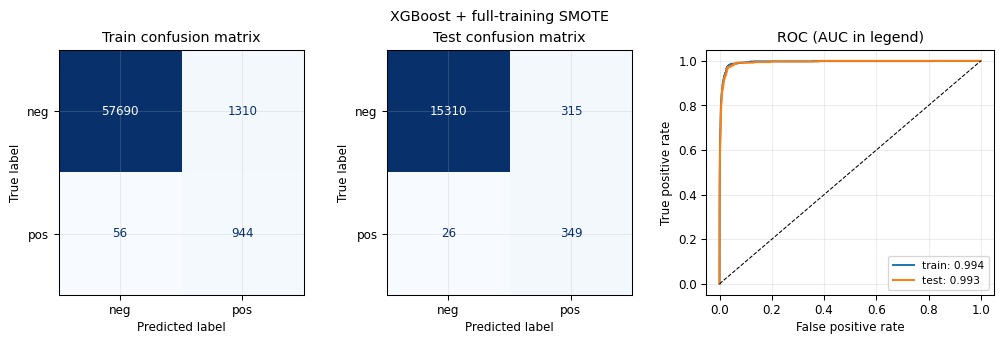

Final SMOTE generated 58,000 positive samples; training becomes 59,000 positive + 59,000 negative.
Selected reg_alpha=10; CV error=0.0240; test error=0.0213.


,model,split,TN,FP,FN,TP,error,balanced_accuracy,AUC
0,XGBoost + full-training SMOTE,train,57690,1310,56,944,0.0228,0.9609,0.9941
1,XGBoost + full-training SMOTE,test,15310,315,26,349,0.0213,0.9553,0.9933


In [6]:
# AI prompt (scope: SMOTE model selection): "For each alpha and each of five stratified folds, fit imputation and scaling on that fold's training rows, apply SMOTE only there, evaluate unchanged validation rows, then refit the selected XGBoost model using all 60,000 original training rows."
smote_cv, smote_alpha = cv_xgb_alpha(X_train, y_train, ALPHAS, smote=True)
display(smote_cv.round(4))
smote_xgb = xgb_pipeline(smote_alpha, smote=True).fit(X_train, y_train)
smote_rows = plot_diagnostics("XGBoost + full-training SMOTE", y_train, y_test,
                              smote_xgb, X_train, X_test)
print(f"Final SMOTE generated {smote_xgb.named_steps['smote'].sampling_strategy_[1]:,} "
      "positive samples; training becomes 59,000 positive + 59,000 negative.")
print(f"Selected reg_alpha={smote_alpha:g}; CV error="
      f"{smote_cv.loc[smote_cv.reg_alpha == smote_alpha, 'CV_error'].iloc[0]:.4f}; "
      f"test error={smote_rows[1]['error']:.4f}.")
display(pd.DataFrame(smote_rows).round(4))


### Model comparison

The table compares all four classifiers on the original held-out test set. Because only 375 of 16,000 test observations are positive, ordinary error can hide missed APS failures. Here, class weighting in the forest did not improve test sensitivity: false negatives rose from 116 to 132. Full-training-set SMOTE reduced XGBoost false negatives from 116 to 26 and raised balanced accuracy from 0.8445 to 0.9553, but false positives rose from 26 to 315 and ordinary test error rose from 0.0089 to 0.0213. AUC stayed high for both XGBoost fits. Which model is preferable depends on the cost of a missed APS failure versus an unnecessary inspection.

In [7]:
comparison = pd.DataFrame(rf_rows + plain_rows + smote_rows)
display(comparison.loc[comparison["split"] == "test"].reset_index(drop=True).round(4))


,model,split,TN,FP,FN,TP,error,balanced_accuracy,AUC,OOB_error
0,RF unweighted,test,15609,16,116,259,0.0082,0.8448,0.9941,0.0064
1,RF class-weighted,test,15600,25,132,243,0.0098,0.8232,0.9935,0.0070
2,XGBoost unweighted,test,15599,26,116,259,0.0089,0.8445,0.9958,NaN
3,XGBoost + full-training SMOTE,test,15310,315,26,349,0.0213,0.9553,0.9933,NaN


## 2. ISLR 6.6.3

Increasing the LASSO budget s from zero relaxes the constraint “sum of absolute coefficients ≤ s,” so the fit grows more flexible. The answers are: (a) training RSS steadily decreases (iv, non-increasing); (b) expected test RSS first decreases and then increases (ii), though its exact shape is not guaranteed for a particular sample; (c) variance steadily increases (iii); (d) squared bias steadily decreases (iv); and (e) irreducible error remains constant (v). The tradeoff in (b) is the bias-variance tradeoff.

## 3. ISLR 6.6.5

Let xᵢ denote the two identical predictor columns and let t = β₁ + β₂. With zero intercept, the ridge objective is “sum over i of [yᵢ − xᵢ(β₁ + β₂)]² + λ(β₁² + β₂²).” For fixed t, its residual term is unchanged and the squared-coefficient penalty is uniquely minimized at β₁ = β₂ = t/2. Thus ridge gives equal coefficients.

The LASSO objective replaces that penalty with λ(|β₁| + |β₂|). For fixed optimal t ≠ 0, every same-sign pair whose coefficients add to t has the same penalty |t| and the same predictions, so the LASSO coefficients are non-unique. If the optimum is t = 0, both coefficients are zero. This answers (a)–(d).

## 4. ISLR 8.4.5

Six of the ten trees assign red probability above 0.5, so majority vote predicts **red** (6 to 4). Their average red probability is 0.45, below 0.5, so averaging probabilities predicts **green**. These combination rules need not agree.

## 5. ISLR 9.7.3

The seven observations are plotted below. The maximal-margin separator is 1 − 2X₁ + 2X₂ = 0, or X₂ = X₁ − 0.5: predict red when the left-hand side is positive and blue otherwise. Its support vectors are observations 2, 3, 5, and 6; each is 1/√8 ≈ 0.354 from the line, so the full margin width is 2/√8 ≈ 0.707. Observation 7 is farther from the margin; a slight movement of it does not change the maximal-margin line. The dashed line X₂ = X₁ − 0.7 still separates the original classes but has a smaller minimum margin. Adding a red point at (3, 1.5), inside the convex hull of the blue observations, makes linear separation impossible.

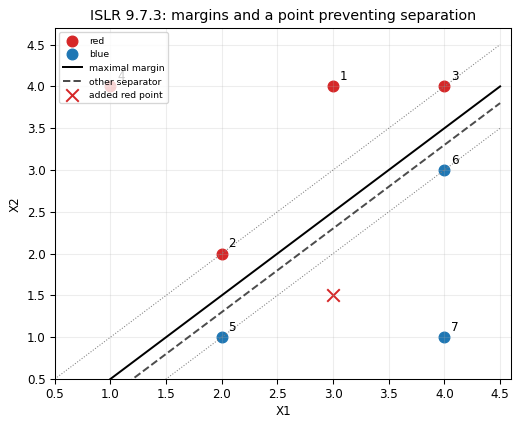

Numerical hard-margin fit: [-1.9994  1.9994] intercept 0.9997 support observations [5, 6, 2, 3]


In [8]:
svm = plot_svm_exercise()
print("Numerical hard-margin fit:", np.round(svm.coef_[0], 4),
      "intercept", round(svm.intercept_[0], 4),
      "support observations", (svm.support_ + 1).tolist())


## References

- [APS Failure at Scania Trucks, UCI](https://archive.ics.uci.edu/dataset/421/aps+failure+at+scania+trucks); supplied files and license information are included in `data/`.
- [ISLR, first edition](https://www.stat.berkeley.edu/~rabbee/s154/ISLR_First_Printing.pdf), Exercises 6.8.3, 6.8.5, 8.4.5, and 9.7.3.
- [scikit-learn imputation guide](https://scikit-learn.org/stable/modules/impute.html) and [imbalanced-learn ensemble/SMOTE documentation](https://imbalanced-learn.org/stable/ensemble.html).
- [XGBoost tree parameters](https://xgboost.readthedocs.io/en/stable/parameter.html), including `reg_alpha`.
